# 컨텍스트 윈도

**이 노트북에서 할 일**

1. 시스템 지시, 문서, 질문의 토큰 수를 세고, 채팅 템플릿으로 합친 실제 입력의 토큰 수와 비교합니다.
2. 한도에서 출력 몫을 빼 입력 한도를 구하고, 문서가 길어지면 언제 한도를 넘는지 확인합니다.
3. 넘친 입력의 끝을 자르면 무엇이 사라지는지 보고, 출력 몫을 줄이면 모델의 답이 끊기는지 확인합니다.

**준비물** — API 키는 필요 없습니다. 인터넷 서비스의 모델을 부르지 않고, 내 컴퓨터에서 작은 언어 모델을 실행합니다.
그래서 비용은 들지 않습니다. 모델이 답을 만드는 계산은 모두 2번 합니다.

실행 시간은 2분 안팎입니다. 모델 파일은 03절과 같은 약 1GB(954MiB)이고, 캐시에 없으면 Hugging Face 사이트에서 내려받습니다.
노트북과 같은 계산을 스크립트로 실행했을 때 Python이 쓴 메모리는 최대 약 3.3GB였습니다.

**기준 버전** — 실습 폴더에 고정한 transformers 4.56.2와 torch 2.8.0을 씁니다.
모델은 `Qwen/Qwen2.5-0.5B-Instruct`이고, 판 번호(revision)를 `7ae557604adf67be50417f59c2c2f167def9a775`로 고정해 받습니다.

교재 출력은 Linux의 Python 3.12.13과 CPU용 torch(2.8.0+cpu)로 만들었습니다. 다른 버전, GPU, Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part1/ch05-llm-principles`에서 01절과 같은 `.venv` 커널을 고른 뒤 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

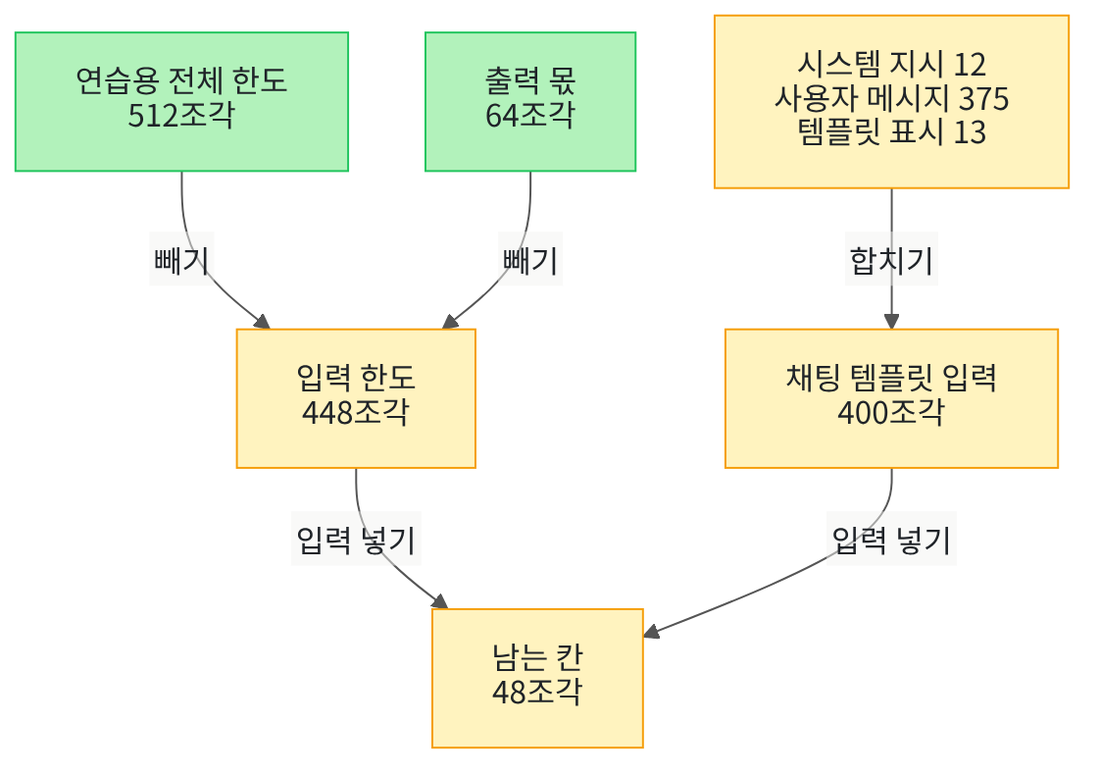

위에서 아래로 읽습니다. 초록 상자는 우리가 정한 한도와 출력 몫이고, 노란 상자는 출력으로 확인하는 조각 수입니다.
왼쪽 갈래는 한도에서 출력 몫을 빼 입력 한도를 구합니다. 오른쪽 갈래는 세 가지 조각을 합쳐 실제 입력을 만들고, 두 갈래가 만나 남는 칸이 나옵니다.

## 1. 준비

이 절은 파일을 읽거나 만들지 않습니다. 준비 셀에서는 transformers 패키지를 불러오고 버전을 확인합니다.

함수 `warnings.filterwarnings()` 줄은 01절처럼 진행 표시 위젯이 없다는 경고 한 줄을 끕니다.
함수 `transformers.logging.set_verbosity_error()`는 transformers의 안내 경고 가운데 오류가 아닌 것을 화면에 내지 않게 합니다.
이 줄이 없으면 9절 생성 셀에서 안내 두 줄이 나옵니다. 어떤 안내인지는 9절 결과 읽기에 적습니다.

In [1]:
# transformers 패키지를 불러오고, 오류가 아닌 안내 경고를 줄인 뒤 버전을 확인합니다
import warnings

# 진행 표시 위젯이 없다는 경고(TqdmWarning)는 계산과 관계없어 화면에 내지 않습니다
warnings.filterwarnings("ignore", message="IProgress not found")

import transformers
from transformers import AutoModelForCausalLM, AutoTokenizer

# 9절 생성 셀의 안내 두 줄(오류 아님)을 화면에 내지 않습니다
transformers.logging.set_verbosity_error()
print("transformers 버전:", transformers.__version__)

transformers 버전: 4.56.2


**결과 읽기** — 출력 줄은 `transformers 버전: 4.56.2`입니다. 준비물에 적은 기준 버전과 같습니다.

## 2. 모델과 모델의 길이 한도

컨텍스트 윈도(context window)는 모델이 한 번 계산할 때 함께 볼 수 있는 토큰 수의 한도입니다.
칸 수가 정해진 달걀판에 그보다 많은 달걀을 담을 수 없는 것과 비슷합니다. 이 셀에서는 설정 파일에 적힌 값으로 이 모델의 한도를 봅니다.

모델은 03절과 같은 Qwen2.5-0.5B-Instruct이고, 같은 판 번호로 받습니다. 이번에는 어텐션 비중을 꺼내지 않으므로 인자 `attn_implementation`을 주지 않습니다.
속성 `model.config.max_position_embeddings`는 모델 설정에 적힌, 한 번에 다룰 자리 수의 한도입니다. 속성 `tokenizer.model_max_length`는 토큰화기 설정에 적힌 최대 길이입니다.

실행 전에 예상합니다. 같은 모델의 설정이니 두 값이 같을 것입니다.

In [2]:
# 03절과 같은 언어 모델과 토큰화기를 받고, 설정에 적힌 길이 한도 두 가지를 봅니다
model_name = "Qwen/Qwen2.5-0.5B-Instruct"
model_revision = "7ae557604adf67be50417f59c2c2f167def9a775"
tokenizer = AutoTokenizer.from_pretrained(model_name, revision=model_revision)
model = AutoModelForCausalLM.from_pretrained(model_name, revision=model_revision)
# 모델 설정에 적힌 자리 수 한도와 토큰화기 설정에 적힌 최대 길이입니다
print("모델 설정 max_position_embeddings:", model.config.max_position_embeddings)
print("토큰화기 설정 model_max_length:", tokenizer.model_max_length)

모델 설정 max_position_embeddings: 32768
토큰화기 설정 model_max_length: 131072


**결과 읽기** — 출력 줄은 `모델 설정 max_position_embeddings: 32768`과 `토큰화기 설정 model_max_length: 131072`입니다. 예상과 달리 두 값이 다릅니다.

이 모델의 모델 카드는 전체 길이 32,768토큰, 생성 8,192토큰이라고 적습니다. 모델 설정 값과 같습니다.
131072는 128 × 1024이고, 모델 카드 앞부분의 Qwen2.5 시리즈 소개에는 128K까지라고 적혀 있습니다. 설정 값 하나만 보고 한도를 정하지 않고, 모델 카드와 함께 확인합니다.

모델 설정과 모델 카드가 같은 32768을 적었으므로, 05절부터는 이 값을 이 모델의 전체 한도로 씁니다. 131072에 가까운 입력은 이번에 실행하지 않았습니다.

이 노트북의 출력은 2026-09-16에 이 모델과 판 번호로 실행한 결과입니다.

## 3. 입력을 이루는 세 부분

에이전트가 모델에 보내는 입력에는 질문만 들어가지 않습니다. 이 절의 입력은 시스템 지시, 문서, 질문의 세 부분입니다.
시스템 지시(system instruction)는 모델이 답하는 규칙을 적은 글입니다. 문서는 답의 근거로 넣는 글이고, 질문은 사용자가 묻는 글입니다.

소재는 01절 둘째 문장 쌍의 환불 기준입니다. 문서는 환불 문장 하나를 `for`와 `+`로 20번 이어 붙인 연습용 글입니다.
01절에서 같은 문장을 여러 번 이어 붙인 모양과 같습니다. 실행 전에 예상합니다. 환불 문장이 끝 공백까지 25글자이니, 문서는 500글자일 것입니다.

In [3]:
# 시스템 지시, 문서, 질문 세 부분의 글을 만듭니다
system_text = "주어진 문서 범위에서만 답하세요."
question = "환불은 며칠 이내에 신청하나요?"
refund_sentence = "환불은 결제일로부터 7일 이내에 신청합니다. "
# 문서는 환불 문장을 20번 이어 붙인 연습용 글입니다
document = ""
for i in range(20):
    document = document + refund_sentence
print("문서 글자 수:", len(document))

문서 글자 수: 500


**결과 읽기** — 출력 줄은 `문서 글자 수: 500`입니다. 예상대로 25글자 문장을 20번 이었습니다.

세 부분을 01절 메서드 `encode()`로 각각 토큰 ID 목록으로 바꾸고, 목록의 길이로 토큰 수를 셉니다.
세 부분은 딕셔너리에 이름과 글로 담고, Ch 2 03절 메서드 `items()`로 하나씩 꺼냅니다.
실행 전에 예상합니다. 글이 가장 긴 문서가 토큰도 가장 많이 쓸 것입니다.

In [4]:
# 세 부분을 따로 토큰으로 바꿔 조각 수를 세고 합을 구합니다
part_texts = {"시스템 지시": system_text, "문서": document, "질문": question}
parts_total = 0
print("부분 | 토큰 수")
for part_name, text in part_texts.items():
    count = len(tokenizer.encode(text))
    parts_total = parts_total + count
    print(part_name, "|", count)
print("세 부분의 합:", parts_total)

부분 | 토큰 수
시스템 지시 | 12
문서 | 360
질문 | 15
세 부분의 합: 387


**결과 읽기** — 라벨 줄 아래 세 줄은 `시스템 지시 | 12`, `문서 | 360`, `질문 | 15`입니다. 마지막 줄은 `세 부분의 합: 387`입니다.

예상대로 문서가 387개 가운데 360개를 씁니다. 360을 반복 수 20으로 나누면, 환불 문장 하나가 18조각입니다.
시스템 지시와 질문도 짧지만 토큰을 씁니다. 세 부분은 한도 하나를 함께 나눠 씁니다.

## 4. 채팅 템플릿으로 합친 실제 입력

채팅 모델에는 세 부분을 따로 넣지 않고, 메시지 목록 하나로 넣습니다. 메시지 하나는 역할(role)과 내용(content)을 담은 딕셔너리입니다.
시스템 지시는 역할 `"system"` 메시지에 넣습니다. 문서와 질문은 줄바꿈 두 개로 이어 역할 `"user"` 메시지에 넣습니다.

채팅 템플릿(chat template)은 메시지 목록을 모델이 배운 모양의 글 하나로 합치는 규칙입니다.
신청서 양식에 이름 칸과 내용 칸이 정해져 있는 것과 비슷합니다. 메서드 `apply_chat_template()`이 이 규칙을 적용합니다.

인자 `tokenize=False`를 주면 토큰 ID가 아니라 글로 반환합니다. 인자 `add_generation_prompt=True`는 글 끝에 모델의 답이 시작될 자리 표시를 붙입니다.
합친 글이 길어서 앞 70글자와 끝 50글자만 슬라이싱으로 봅니다. 실행 전에 예상합니다. 합친 글에는 역할 이름 system과 user가 들어 있을 것입니다.

In [5]:
# 시스템 메시지와 사용자 메시지를 목록에 담고, 채팅 템플릿으로 합친 글의 앞뒤를 봅니다
user_text = document + "\n\n" + question
messages = [
    {"role": "system", "content": system_text},
    {"role": "user", "content": user_text},
]
# tokenize=False는 글로 반환하고, add_generation_prompt=True는 답이 시작될 표시를 붙입니다
template_text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
text_length = len(template_text)
print("합친 글의 앞 70글자:")
print(template_text[0:70])
print("합친 글의 끝 50글자:")
print(template_text[text_length - 50:text_length])

합친 글의 앞 70글자:
<|im_start|>system
주어진 문서 범위에서만 답하세요.<|im_end|>
<|im_start|>user
환불은 결
합친 글의 끝 50글자:
환불은 며칠 이내에 신청하나요?<|im_end|>
<|im_start|>assistant



**결과 읽기** — 첫 라벨 줄 아래 글은 `<|im_start|>system`으로 시작합니다. 둘째 라벨 줄 아래 글은 `<|im_start|>assistant`로 끝납니다.

표시 `<|im_start|>`는 메시지의 시작을, `<|im_end|>`는 메시지의 끝을 나타냅니다. 예상대로 역할 이름 system과 user가 들어 있습니다.
끝의 `<|im_start|>assistant` 줄은 인자 `add_generation_prompt=True`가 붙인 자리 표시입니다. 모델은 이 뒤에 답을 이어 씁니다.

합친 글을 `encode()`로 바꿔 실제 입력의 토큰 수를 셉니다. 비교를 위해 사용자 메시지 하나의 토큰 수도 셉니다.
실행 전에 예상합니다. 채팅 템플릿의 표시가 더해졌으니, 실제 입력은 3절의 합 387보다 조금 많을 것입니다.

In [6]:
# 합친 글을 토큰으로 바꿔 실제 입력의 조각 수를 세고, 세 부분의 합과 비교합니다
input_id_list = tokenizer.encode(template_text)
input_length = len(input_id_list)
user_length = len(tokenizer.encode(user_text))
print("사용자 메시지 토큰 수:", user_length)
print("실제 입력 토큰 수:", input_length)
print("세 부분의 합보다 늘어난 수:", input_length - parts_total)

사용자 메시지 토큰 수: 375
실제 입력 토큰 수: 400
세 부분의 합보다 늘어난 수: 13


**결과 읽기** — 출력 줄은 `사용자 메시지 토큰 수: 375`, `실제 입력 토큰 수: 400`, `세 부분의 합보다 늘어난 수: 13`입니다.

시스템 지시 12개와 사용자 메시지 375개를 더하면 387개로, 3절의 합과 같습니다. 여기에 템플릿이 조각 13개를 더했습니다.
모델의 한도와 비교할 수는 세 부분의 합 387이 아니라 실제 입력 400입니다.

늘어난 13조각을 확인합니다. 실제 입력의 앞 세 조각과 끝 다섯 조각을 01절처럼 `decode()`로 하나씩 글자로 바꿉니다.
목록을 출력하면 줄바꿈 글자는 `'\n'`으로 보입니다. 실행 전에 예상합니다. 앞 조각에는 system이, 끝 조각에는 assistant가 보일 것입니다.

In [7]:
# 실제 입력의 앞 세 조각과 끝 다섯 조각을 글자로 바꿔, 템플릿이 더한 표시를 봅니다
first_pieces = []
for token_id in input_id_list[0:3]:
    first_pieces.append(tokenizer.decode([token_id]))
last_pieces = []
for token_id in input_id_list[input_length - 5:input_length]:
    last_pieces.append(tokenizer.decode([token_id]))
print("앞 세 조각:", first_pieces)
print("끝 다섯 조각:", last_pieces)

앞 세 조각: ['<|im_start|>', 'system', '\n']
끝 다섯 조각: ['<|im_end|>', '\n', '<|im_start|>', 'assistant', '\n']


**결과 읽기** — 출력 줄은 `앞 세 조각: ['<|im_start|>', 'system', '\n']`과 `끝 다섯 조각: ['<|im_end|>', '\n', '<|im_start|>', 'assistant', '\n']`입니다.

예상대로 표시 `<|im_start|>`는 조각 하나이고, 역할 이름과 줄바꿈도 조각 하나씩입니다. 앞뒤를 합쳐 8조각입니다.
나머지 5조각은 시스템 메시지와 사용자 메시지 사이에 있습니다. 4절 첫 출력에서 `<|im_end|>`, 줄바꿈, `<|im_start|>`, user, 줄바꿈으로 보인 부분입니다.

## 5. 값 바꿔 보기 — 시스템 메시지 빼기

바꾸는 값은 메시지 목록입니다. 시스템 메시지를 빼고 사용자 메시지 하나만 넣습니다. 사용자 메시지 글은 그대로입니다.

실행 전에 예상합니다. 시스템 지시 12조각과 그 앞뒤 표시 5조각이 빠집니다. 그러면 실제 입력은 400에서 17을 뺀 383개쯤일 것입니다.

In [8]:
# 시스템 메시지를 뺀 목록으로 채팅 템플릿을 다시 적용해, 토큰 수와 합친 글의 앞부분을 봅니다
user_only_messages = [
    {"role": "user", "content": user_text},
]
user_only_text = tokenizer.apply_chat_template(user_only_messages, tokenize=False, add_generation_prompt=True)
user_only_length = len(tokenizer.encode(user_only_text))
print("시스템 메시지를 뺀 입력 토큰 수:", user_only_length)
print("합친 글의 앞 90글자:")
print(user_only_text[0:90])

시스템 메시지를 뺀 입력 토큰 수: 404
합친 글의 앞 90글자:
<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|i


**결과 읽기** — 출력 줄은 `시스템 메시지를 뺀 입력 토큰 수: 404`입니다. 예상과 달리 400보다 4개 늘었습니다.

라벨 줄 아래 글을 보면, 템플릿이 영어 기본 지시 `You are Qwen, created by Alibaba Cloud.`을 넣었습니다.
이 모델의 채팅 템플릿은 첫 메시지가 시스템 메시지가 아니면 이 기본 지시를 넣습니다. 그래서 시스템 지시를 빼도 입력이 줄지 않을 수 있습니다.
다음 절부터는 다시 4절의 메시지 목록을 씁니다.

## 6. 한도에서 출력 몫 빼기

모델이 만드는 답의 조각도 같은 한도 안에 들어갑니다. 그래서 답을 위한 칸을 먼저 떼어 두고, 남은 칸에 입력을 넣습니다.
이렇게 한도를 입력과 출력에 나눠 배정하는 계획을 토큰 예산(token budget)이라고 부릅니다. 식은 `입력 한도 = 전체 한도 - 출력 몫`입니다.

이 모델의 한도 32768에 비하면 400조각짜리 입력은 너무 작아 차이가 잘 보이지 않습니다. 그래서 연습용 전체 한도를 512로 정합니다.
모델은 이 연습용 한도를 모릅니다. 입력이 한도를 넘는지는 우리 코드가 계산해 확인합니다.

실행 전에 예상합니다. 출력 몫이 64이면 입력 한도는 448이고, 입력 400을 넣으면 48칸이 남을 것입니다.
출력 몫이 128이면 입력 한도가 384라서, 입력 400이 들어갈 칸이 모자랄 것입니다.

In [9]:
# 연습용 전체 한도 512에서 출력 몫을 빼 입력 한도를 구하고, 실제 입력을 넣고 남는 칸을 봅니다
practice_window = 512
print("출력 몫 | 입력 한도 | 남는 칸")
for output_budget in [32, 64, 128]:
    input_budget = practice_window - output_budget
    remaining = input_budget - input_length
    print(output_budget, "|", input_budget, "|", remaining)

출력 몫 | 입력 한도 | 남는 칸
32 | 480 | 80
64 | 448 | 48
128 | 384 | -16


**결과 읽기** — 라벨 줄 아래 세 줄은 `32 | 480 | 80`, `64 | 448 | 48`, `128 | 384 | -16`입니다.

예상대로 출력 몫 64에서는 48칸이 남습니다. 출력 몫 128에서는 남는 칸이 -16으로, 입력이 16조각 넘칩니다.
입력이 그대로여도 출력 몫을 늘리면 한도를 넘을 수 있습니다.

## 7. 문서가 길어지면

이번에는 출력 몫을 64로 두고, 문서의 반복 수를 바꿔 입력이 언제 448을 넘는지 봅니다.
반복 수마다 같은 계산을 하므로 함수 두 개를 만듭니다. 먼저 반복 수를 받아 문서 글을 반환하는 함수입니다. 이 셀은 함수를 정의만 합니다.

In [10]:
# 환불 문장을 반복 수만큼 이어 붙인 문서 글을 반환하는 함수를 정의합니다
def make_document(repeat):
    document_text = ""
    for i in range(repeat):
        document_text = document_text + refund_sentence
    return document_text

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

다음 함수는 문서 글을 받아 4절과 같은 메시지 목록을 만들고, 채팅 템플릿으로 합친 글을 반환합니다. 이 셀도 함수를 정의만 합니다.

In [11]:
# 문서 글로 시스템·사용자 메시지 목록을 만들고, 채팅 템플릿으로 합친 입력 글을 반환하는 함수를 정의합니다
def make_input_text(document_text):
    message_list = [
        {"role": "system", "content": system_text},
        {"role": "user", "content": document_text + "\n\n" + question},
    ]
    return tokenizer.apply_chat_template(message_list, tokenize=False, add_generation_prompt=True)

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

반복 수 10, 20, 22, 23, 40, 80으로 입력 토큰 수를 세고, 입력 한도 448 이하인지 봅니다.
실행 전에 예상합니다. 환불 문장 하나가 18조각이니 반복을 하나 늘릴 때마다 18조각씩 늘 것입니다.
20번이 400이면 22번은 436으로 들어가고, 23번은 454로 448을 넘을 것입니다.

In [12]:
# 출력 몫 64를 뺀 입력 한도 448과, 반복 수마다 채팅 템플릿 입력의 토큰 수를 비교합니다
output_budget = 64
input_budget = practice_window - output_budget
print("반복 수 | 입력 토큰 수 | 448 이하")
for repeat in [10, 20, 22, 23, 40, 80]:
    document_text = make_document(repeat)
    input_text = make_input_text(document_text)
    token_count = len(tokenizer.encode(input_text))
    print(repeat, "|", token_count, "|", token_count <= input_budget)

반복 수 | 입력 토큰 수 | 448 이하
10 | 220 | True
20 | 400 | True
22 | 436 | True
23 | 454 | False
40 | 760 | False
80 | 1480 | False


**결과 읽기** — 라벨 줄 아래 여섯 줄은 `10 | 220 | True`, `20 | 400 | True`, `22 | 436 | True`, `23 | 454 | False`, `40 | 760 | False`, `80 | 1480 | False`입니다.

예상대로 반복을 하나 늘릴 때마다 18조각씩 늘었습니다. 입력 한도 448에 들어가는 가장 긴 문서는 22번 이은 문서입니다.
10번의 220에서 문서 180조각을 빼면 40조각이 남습니다. 시스템 지시 12, 질문 15, 표시 13을 더한 40조각은 반복 수와 관계없이 늘 들어갑니다.

## 8. 한도를 넘는 입력을 자르면

40번 이은 문서의 입력은 760조각이라 입력 한도 448을 넘습니다. 넘치는 입력을 줄이는 가장 단순한 방법은 한쪽 끝을 잘라 448조각만 남기는 것입니다.
토큰 ID 목록을 슬라이싱해서 앞 448개만 남긴 경우와 뒤 448개만 남긴 경우를 비교합니다.
남긴 ID는 `decode()`로 글로 바꾸고, 연산자 `in`으로 시스템 지시, 질문, 답 시작 표시가 남았는지 확인합니다.

실행 전에 예상합니다. 앞쪽을 남기면 끝에 있던 질문과 답 시작 표시가 사라질 것입니다. 뒤쪽을 남기면 맨 앞의 시스템 지시가 사라질 것입니다.

In [13]:
# 40번 이은 문서의 입력에서 앞 448조각과 뒤 448조각만 남긴 글을 만들어, 무엇이 남았는지 봅니다
long_document = make_document(40)
long_text = make_input_text(long_document)
long_ids = tokenizer.encode(long_text)
long_length = len(long_ids)
front_kept = tokenizer.decode(long_ids[0:input_budget])
back_kept = tokenizer.decode(long_ids[long_length - input_budget:long_length])
start_mark = "<|im_start|>assistant"
print("원래 입력 토큰 수:", long_length)
print("남긴 쪽 | 시스템 지시 | 질문 | 답 시작 표시")
print("앞 448조각 |", system_text in front_kept, "|", question in front_kept, "|", start_mark in front_kept)
print("뒤 448조각 |", system_text in back_kept, "|", question in back_kept, "|", start_mark in back_kept)
print("앞 448조각을 남긴 글의 끝 20글자:")
print(front_kept[len(front_kept) - 20:len(front_kept)])

원래 입력 토큰 수: 760
남긴 쪽 | 시스템 지시 | 질문 | 답 시작 표시
앞 448조각 | True | False | False
뒤 448조각 | False | True | True
앞 448조각을 남긴 글의 끝 20글자:
 환불은 결제일로부터 7일 이내에 신


**결과 읽기** — 첫 줄은 `원래 입력 토큰 수: 760`입니다. 표 라벨 줄 아래 두 줄은 `앞 448조각 | True | False | False`와 `뒤 448조각 | False | True | True`입니다.

예상대로 앞쪽을 남기면 질문과 답 시작 표시가, 뒤쪽을 남기면 시스템 지시가 사라졌습니다. 마지막 라벨 줄 아래 글은 문장 가운데서 끊겼습니다.
어느 쪽을 잘라도 입력의 중요한 부분이 빠집니다. 그래서 넘치는 입력은 끝을 자르기 전에, 넣을 문서를 줄이거나 고르는 방법을 먼저 찾습니다.

## 9. 출력 몫으로 답 만들기

이제 모델이 실제로 답을 만들게 합니다. 입력은 4절에서 만든 400조각짜리 글이고, 출력 몫은 64입니다.
03절처럼 메서드 `encode()`에 인자 `return_tensors="pt"`를 주어 텐서로 바꿉니다.

메서드 `generate()`는 입력 뒤에 이어질 조각을 하나씩 골라 붙이고, 입력과 새 조각을 합친 ID 텐서를 반환합니다.
인자 `max_new_tokens`는 새로 만들 조각 수의 상한으로, 이 절의 출력 몫입니다. 인자 `do_sample=False`는 다음 조각을 무작위로 뽑지 않게 합니다.
조각을 고르는 방식은 06절 temperature와 샘플링에서 다룹니다.

반환된 ID 목록의 앞 400개는 입력이므로, 400번 자리부터가 새 조각입니다.
실행 전에 예상합니다. 답은 한 문장이라 64조각보다 짧고, 모델이 끝 표시 `<|im_end|>`를 내며 멈출 것입니다.

In [14]:
# 4절의 입력을 텐서로 바꾸고, 출력 몫 64 안에서 모델이 답을 만들게 합니다
output_budget = 64
input_ids = tokenizer.encode(template_text, return_tensors="pt")
# max_new_tokens는 새로 만들 조각 수의 상한, do_sample=False는 무작위로 뽑지 않는 설정입니다
output_ids = model.generate(input_ids=input_ids, max_new_tokens=output_budget, do_sample=False)
all_ids = output_ids[0].tolist()
# 입력 뒤에 붙은 새 조각만 골라 글로 바꿉니다
new_ids = all_ids[input_length:len(all_ids)]
answer = tokenizer.decode(new_ids)
print("새 조각 수:", len(new_ids))
print("답:", answer)
print("끝 표시로 멈췄는가:", "<|im_end|>" in answer)

새 조각 수: 18
답: 환불은 결제일로부터 7일 이내에 신청합니다.<|im_end|>
끝 표시로 멈췄는가: True


**결과 읽기** — 출력 줄은 `새 조각 수: 18`, `답: 환불은 결제일로부터 7일 이내에 신청합니다.<|im_end|>`, `끝 표시로 멈췄는가: True`입니다.

예상대로 모델은 18조각을 만들고 끝 표시로 멈췄습니다. 입력 400에 새 조각 18을 더한 418은 연습용 한도 512 안입니다.
실행 환경이나 버전이 바뀌면 답 문장이 달라질 수 있습니다.

1절에서 끈 안내 두 줄은 이 셀에서 나옵니다. 하나는 temperature 같은 샘플링 설정 값을 이번 생성에서 쓰지 않는다는 안내입니다.

다른 하나는 어텐션 마스크(attention mask)를 넣지 않았다는 안내입니다. 어텐션 마스크는 모델이 볼 자리를 1과 0으로 표시한 목록입니다.
이 입력에는 길이를 맞추려고 넣는 채움 조각이 없습니다. 이럴 때는 모든 자리를 보는 마스크로 계산한다고, 설치한 4.56.2 소스에서 확인했습니다.

## 10. 값 바꿔 보기 — 출력 몫을 8로 줄이기

바꾸는 값은 출력 몫 하나입니다. 인자 `max_new_tokens`를 64에서 8로 줄이고, 같은 입력으로 다시 답을 만들게 합니다.

실행 전에 예상합니다. 9절의 답은 18조각이었으니, 8조각에서 멈춰 문장이 중간에 끊길 것입니다. 끝 표시도 없을 것입니다.

In [15]:
# 출력 몫만 8로 줄여, 같은 입력으로 다시 답을 만들게 합니다
short_budget = 8
short_output_ids = model.generate(input_ids=input_ids, max_new_tokens=short_budget, do_sample=False)
short_all_ids = short_output_ids[0].tolist()
short_new_ids = short_all_ids[input_length:len(short_all_ids)]
short_answer = tokenizer.decode(short_new_ids)
print("새 조각 수:", len(short_new_ids))
print("답:", short_answer)
print("끝 표시로 멈췄는가:", "<|im_end|>" in short_answer)

새 조각 수: 8
답: 환불은 결제일로부터 
끝 표시로 멈췄는가: False


**결과 읽기** — 출력 줄은 `새 조각 수: 8`과 `끝 표시로 멈췄는가: False`입니다. 답 줄은 `답: 환불은 결제일로부터`에서 끊겼습니다.

예상대로 모델은 답을 다 쓰기 전에 출력 몫 8에서 멈췄습니다. 오류는 나지 않았고, 끊긴 답이 그대로 반환되었습니다.
Ch 4에서 본 「오류 없이 틀린 결과」와 같은 종류입니다. 출력 몫을 너무 작게 잡으면, 오류 메시지 없이 끊긴 답을 받습니다.

## 정리

- 실제 입력은 시스템 지시 12조각과 사용자 메시지 375조각에, 채팅 템플릿의 표시 13조각을 더한 400조각이었습니다. 시스템 메시지를 빼자 기본 지시가 들어가 404조각이 되었습니다.
- 연습용 한도 512에서 출력 몫 64를 빼면 입력 한도는 448입니다. 문서를 23번 이으면 454조각으로 넘쳤고, 40번 이은 입력의 앞쪽만 남기면 질문이 사라졌습니다.
- 출력 몫을 64에서 8로 줄이자, 모델의 답이 8조각에서 끝 표시 없이 끊겼습니다.

한도는 입력과 출력이 함께 나눠 쓰는 칸 수이고, 입력에는 우리가 적지 않은 표시와 기본 지시도 들어갑니다.
다음 05절에서는 한도 안에 들어간 긴 입력에서도, 근거 문장의 위치와 주변 문장 수에 따라 답이 달라지는지 봅니다.